Dimensión de data:   (442, 10)
Dimensión de target: (442,)

--- RESUMEN ESTADÍSTICO DE TARGET ---
count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00
Name: target, dtype: float64

--- CORRELACIONES CON TARGET ---
target    1.0000
bmi       0.5865
s5        0.5659
bp        0.4415
s4        0.4305
s6        0.3825
s1        0.2120
age       0.1879
s2        0.1741
sex       0.0431
s3       -0.3948
Name: target, dtype: float64


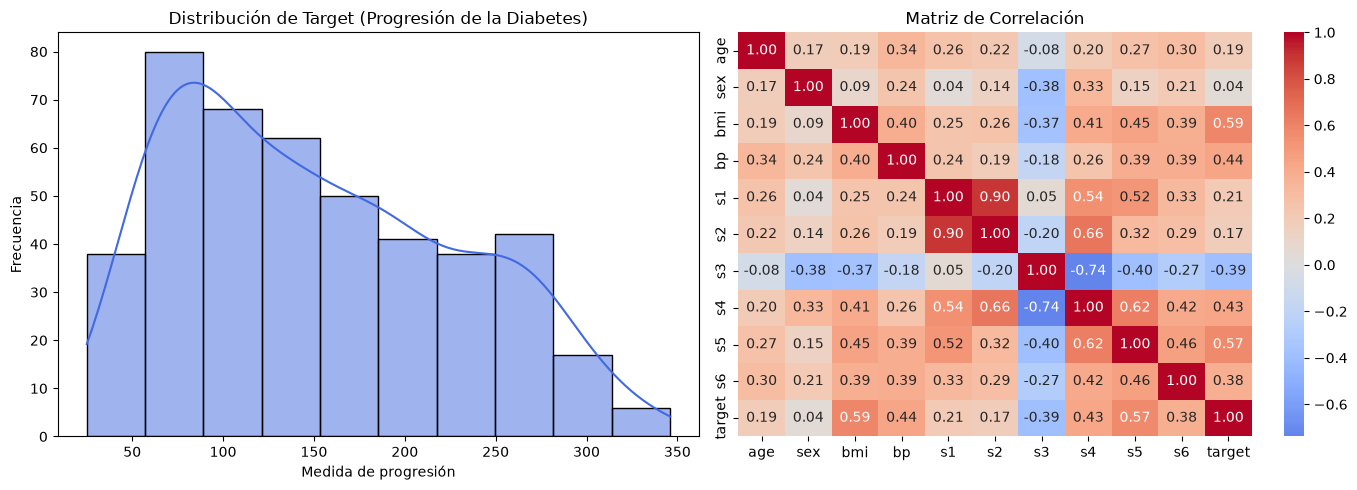


--- PARÁMETROS DEL MODELO AJUSTADO ---
Intercepto: 152.7643
   age:     0.3061
   sex:  -237.6356
   bmi:   510.5380
    bp:   327.7299
    s1:  -814.1119
    s2:   492.7996
    s3:   102.8412
    s4:   184.6035
    s5:   743.5094
    s6:    76.0966

--- REAL VS PREDICCIÓN (CONJUNTO DE TEST) ---
 Valor Real  Predicción  Error (Real - Pred)
      233.0      197.62                35.38
       91.0      155.44               -64.44
      111.0      172.89               -61.89
      152.0      111.53                40.47
      120.0      164.79               -44.79
       67.0      131.07               -64.07
      310.0      259.12                50.88
       94.0      100.48                -6.48
      183.0      117.06                65.94
       66.0      124.30               -58.30
      173.0      218.37               -45.37
       72.0       61.20                10.80
       49.0      132.25               -83.25
       64.0      120.33               -56.33
       48.0       52.55    

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score
)

# 1. Cargar el dataset e inspeccionar dimensiones
diabetes = load_diabetes()
print("Dimensión de data:  ", diabetes['data'].shape)    # (442, 10)
print("Dimensión de target:", diabetes['target'].shape)  # (442,)

# 2. Breve Análisis Exploratorio de Datos (EDA)
df = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
df['target'] = diabetes['target']

print("\n--- RESUMEN ESTADÍSTICO DE TARGET ---")
print(df['target'].describe().round(2))

print("\n--- CORRELACIONES CON TARGET ---")
print(df.corr()['target'].sort_values(ascending=False).round(4))

# Visualizar distribución de la variable objetivo y matriz de correlación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['target'], kde=True, color='royalblue', ax=axes[0])
axes[0].set_title("Distribución de Target (Progresión de la Diabetes)")
axes[0].set_xlabel("Medida de progresión")
axes[0].set_ylabel("Frecuencia")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Matriz de Correlación")

plt.tight_layout()
plt.show()

# 3. División Train / Test (últimos 20 registros para test, el resto para train)
diabetes_data_train = diabetes['data'][:-20]
diabetes_target_train = diabetes['target'][:-20]

diabetes_data_test = diabetes['data'][-20:]
diabetes_target_test = diabetes['target'][-20:]

# 4. Instanciar y entrenar el modelo de Regresión Lineal
diabetes_model = linear_model.LinearRegression()
diabetes_model.fit(diabetes_data_train, diabetes_target_train)

print("\n--- PARÁMETROS DEL MODELO AJUSTADO ---")
print(f"Intercepto: {diabetes_model.intercept_:.4f}")
for feat, coef in zip(diabetes['feature_names'], diabetes_model.coef_):
    print(f"  {feat:>4}: {coef:>10.4f}")

# 5. Predecir y comparar contra los valores reales de test
predictions = diabetes_model.predict(diabetes_data_test)

comparacion = pd.DataFrame({
    'Valor Real': diabetes_target_test,
    'Predicción': np.round(predictions, 2),
    'Error (Real - Pred)': np.round(diabetes_target_test - predictions, 2)
})
print("\n--- REAL VS PREDICCIÓN (CONJUNTO DE TEST) ---")
print(comparacion.to_string(index=False))

# 6. Evaluar con distintas métricas de error
mae = mean_absolute_error(diabetes_target_test, predictions)
mape = mean_absolute_percentage_error(diabetes_target_test, predictions)
mse = mean_squared_error(diabetes_target_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(diabetes_target_test, predictions)

print("\n--- MÉTRICAS DEL MODELO BASE (10 VARIABLES) ---")
print(f"MAE:  {mae:.4f}")
print(f"MAPE: {mape * 100:.2f}%")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 7. Iteración de modelos: StandardScaler y Selección de Variables
# A) Probando StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(diabetes_data_train)
X_test_scaled = scaler.transform(diabetes_data_test)

model_scaled = linear_model.LinearRegression()
model_scaled.fit(X_train_scaled, diabetes_target_train)
pred_scaled = model_scaled.predict(X_test_scaled)

# B) Reducción de variables: Top 2 predictores lineales ('bmi' y 's5')
selector = SelectKBest(score_func=f_regression, k=2)
X_train_top2 = selector.fit_transform(diabetes_data_train, diabetes_target_train)
X_test_top2 = selector.transform(diabetes_data_test)

model_top2 = linear_model.LinearRegression()
model_top2.fit(X_train_top2, diabetes_target_train)
pred_top2 = model_top2.predict(X_test_top2)

# Tabla comparativa de iteraciones
resultados_df = pd.DataFrame({
    'Modelo': [
        '1. Base (Todas las 10 variables)',
        '2. Con StandardScaler (10 variables)',
        '3. Reducido (Top 2: bmi + s5)'
    ],
    'MAE': [
        mean_absolute_error(diabetes_target_test, predictions),
        mean_absolute_error(diabetes_target_test, pred_scaled),
        mean_absolute_error(diabetes_target_test, pred_top2)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(diabetes_target_test, predictions)),
        np.sqrt(mean_squared_error(diabetes_target_test, pred_scaled)),
        np.sqrt(mean_squared_error(diabetes_target_test, pred_top2))
    ],
    'R²': [
        r2_score(diabetes_target_test, predictions),
        r2_score(diabetes_target_test, pred_scaled),
        r2_score(diabetes_target_test, pred_top2)
    ]
})

print("\n--- COMPARATIVA ENTRE ITERACIONES ---")
print(resultados_df.to_string(index=False))